In [2]:
import requests
import json
import matplotlib.pyplot as plt

In [3]:
# 동영상 ID
video_id = "Cbij3MKhdOY"

In [4]:
event_lst = [13, 15, 21, 43, 45, 52, 62, 68, 73, 97]

In [5]:
json_path = f'/source/ms/highlight/json/{video_id}.json'

In [6]:
with open(json_path, 'r') as json_file:
    data = json.load(json_file)

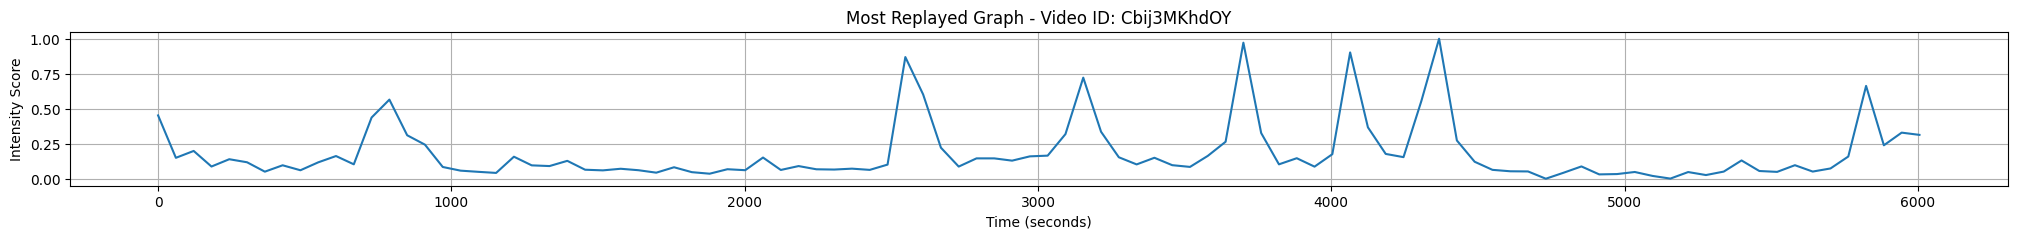

In [7]:



# # API 엔드포인트 URL
# url = f"https://yt.lemnoslife.com/videos?part=mostReplayed&id={video_id}"

# # API 호출하여 JSON 데이터 가져오기
# print('get url!!!')
# response = requests.get(url)
# print('get url finished!!!!!')
# data = response.json()

# markers 리스트에서 startMillis와 intensityScoreNormalized 값 추출
markers = data['items'][0]['mostReplayed']['markers']
start_millis = [marker['startMillis'] for marker in markers]
intensity_scores = [marker['intensityScoreNormalized'] for marker in markers]

# 밀리초를 초로 변환
start_seconds = [millis / 1000 for millis in start_millis]

# 그래프 그리기
plt.figure(figsize=(25, 2))
plt.plot(start_seconds, intensity_scores)
plt.title(f'Most Replayed Graph - Video ID: {video_id}')
plt.xlabel('Time (seconds)')
plt.ylabel('Intensity Score')
plt.grid(True)
plt.show()


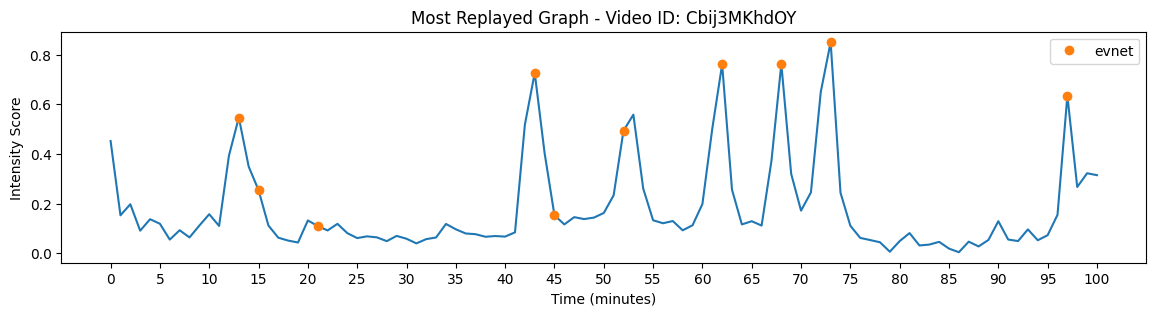

In [8]:
# 보간 함수 생성
from scipy.interpolate import interp1d
import numpy as np
from scipy.signal import find_peaks

interpolation_function = interp1d(start_seconds, intensity_scores, kind='linear', fill_value="extrapolate")

# 1초 간격으로 새로운 시간 생성
total_duration_seconds = start_seconds[-1]
total_duration_minutes = total_duration_seconds / 60
new_time = np.arange(0, total_duration_minutes, 1) * 60
# new_time = np.arange(0, total_duration_seconds, 1)

# 새로운 시간에 대한 보간된 값 계산
smoothed_intensity_scores = interpolation_function(new_time)
# peaks, _ = find_peaks(smoothed_intensity_scores, prominence = 0.1)

# 그래프 그리기
plt.figure(figsize=(14, 3))
plt.plot(new_time / 60, smoothed_intensity_scores)  # 분으로 변환하여 표시
plt.plot(np.array(event_lst) , smoothed_intensity_scores[event_lst], "o", label='evnet')
plt.title(f'Most Replayed Graph - Video ID: {video_id}')
plt.xlabel('Time (minutes)')
plt.ylabel('Intensity Score')
# plt.grid(True)
plt.xticks(np.arange(0, total_duration_minutes + 1, 5))  # 5분 간격으로 x축 눈금 표시
plt.legend()
plt.show()

# normalize

In [9]:
import numpy as np

def normalize_array(arr):
    min_val = np.min(arr)
    max_val = np.max(arr)
    
    # 0으로 나누는 것을 방지하기 위한 체크
    if max_val == min_val:
        return np.zeros_like(arr)
    
    normalized_arr = (arr - min_val) / (max_val - min_val)
    return normalized_arr

# 정규화 적용
normalized_scores = normalize_array(smoothed_intensity_scores)

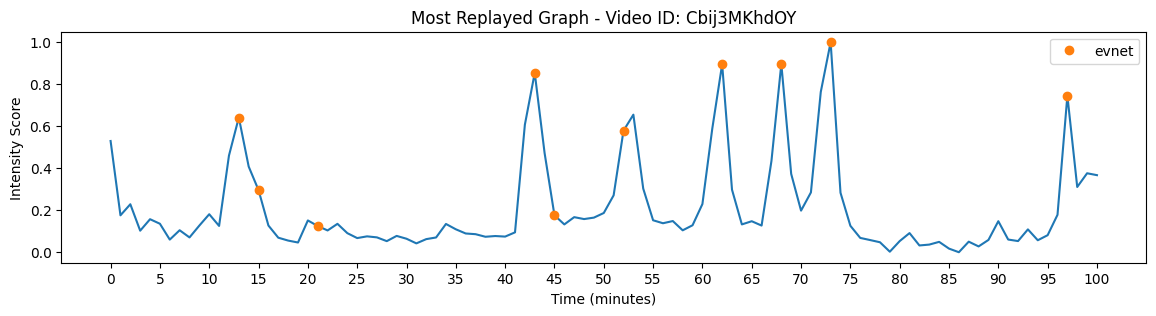

In [10]:
plt.figure(figsize=(14, 3))
plt.plot(new_time / 60, normalized_scores)  # 분으로 변환하여 표시
plt.plot(np.array(event_lst) , normalized_scores[event_lst], "o", label='evnet')
plt.title(f'Most Replayed Graph - Video ID: {video_id}')
plt.xlabel('Time (minutes)')
plt.ylabel('Intensity Score')
# plt.grid(True)
plt.xticks(np.arange(0, total_duration_minutes + 1, 5))  # 5분 간격으로 x축 눈금 표시
plt.legend()
plt.show()

# 소리 크기

In [11]:
from moviepy.editor import VideoFileClip
import librosa
import numpy as np
import matplotlib.pyplot as plt

# # 비디오 파일 경로
# video_path = "C:/Users/vml_sub/Documents/Minsun2024/highlight/source/Cbij3MKhdOY.mp4"

# # 비디오에서 오디오 추출
# video = VideoFileClip(video_path)
# audio = video.audio
# audio.write_audiofile("temp_audio.wav")



# 임시 오디오 파일 삭제
import os
# os.remove("temp_audio.wav")

In [12]:
# 오디오 파일 로드
# y, sr = librosa.load("soccer.wav")
y, sr = librosa.load("combined_output_accom.wav")

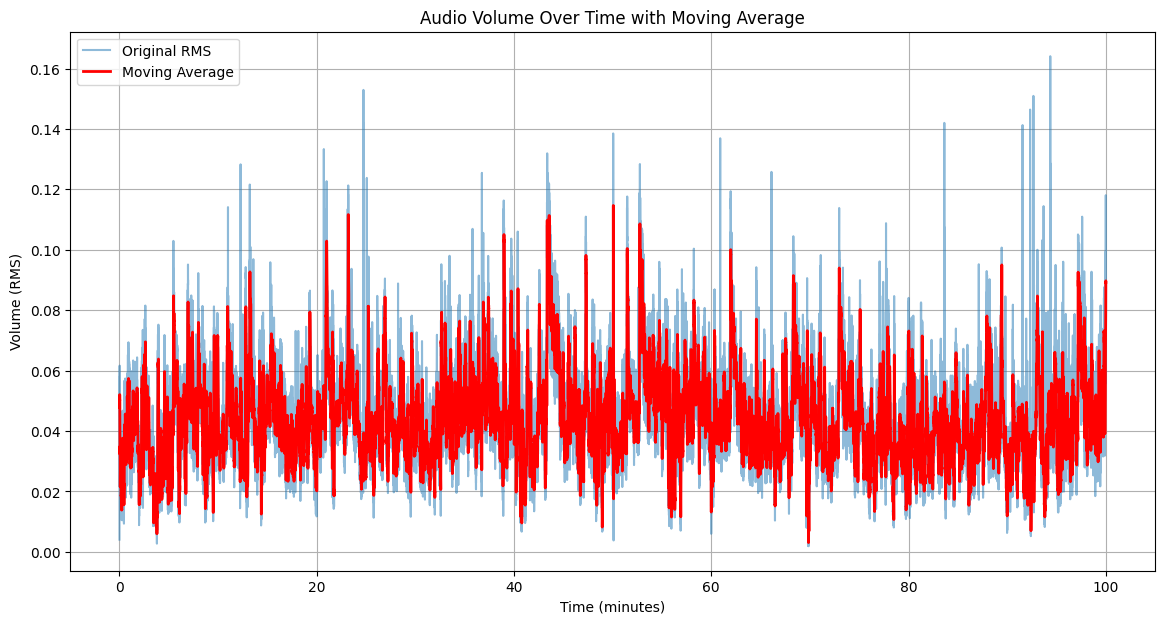

In [19]:
# Calculate RMS (Root Mean Square)
import pandas as pd

frame_length = 2048
hop_length = 512
rms = librosa.feature.rms(y=y, frame_length=frame_length, hop_length=hop_length)[0]

# Convert RMS to pandas Series
rms_series = pd.Series(rms)



ValueError: x and y must have same first dimension, but have shapes (258399,) and (255400,)

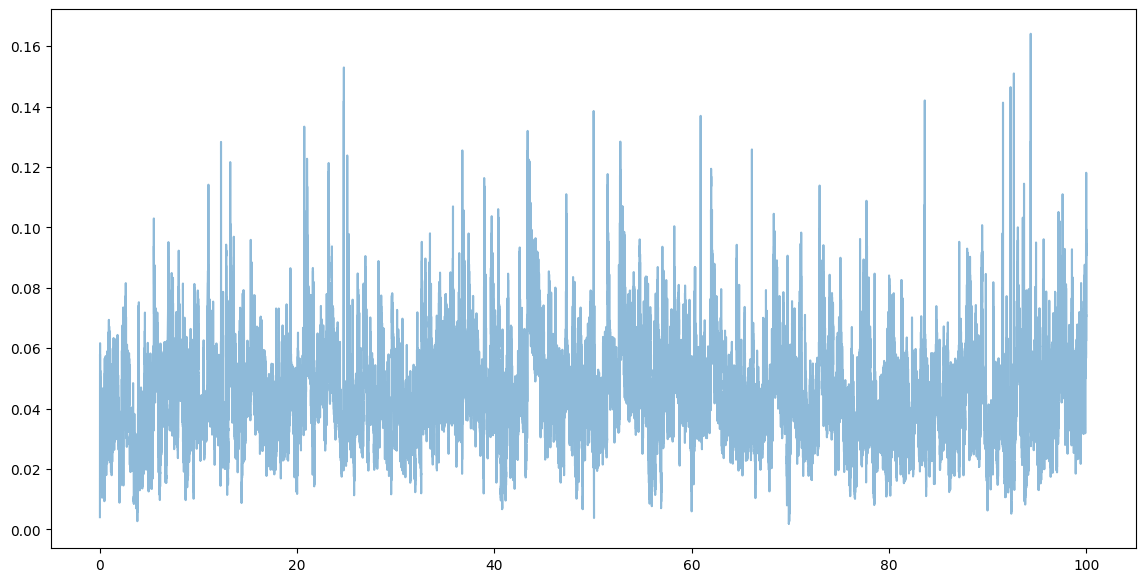

In [34]:
# Calculate the moving average
window_size = 3000  # Adjust window size for smoothing level
moving_avg = rms_series.rolling(window=window_size, center=True).mean()

# Timmoving_avg = moving_avg.dropna()e axis in minutes
time_axis = np.arange(len(rms)) * hop_length / sr / 60

# Plotting
plt.figure(figsize=(14, 7))
plt.plot(time_axis, rms_series, label='Original RMS', alpha=0.5)
plt.plot(time_axis, moving_avg, color='red', label='Moving Average', linewidth=2)
plt.title('Audio Volume Over Time with Moving Average')
plt.xlabel('Time (minutes)')
plt.ylabel('Volume (RMS)')
plt.legend()
plt.grid(True)
plt.show()

In [31]:
moving_avg_normalize = normalize(moving_avg)

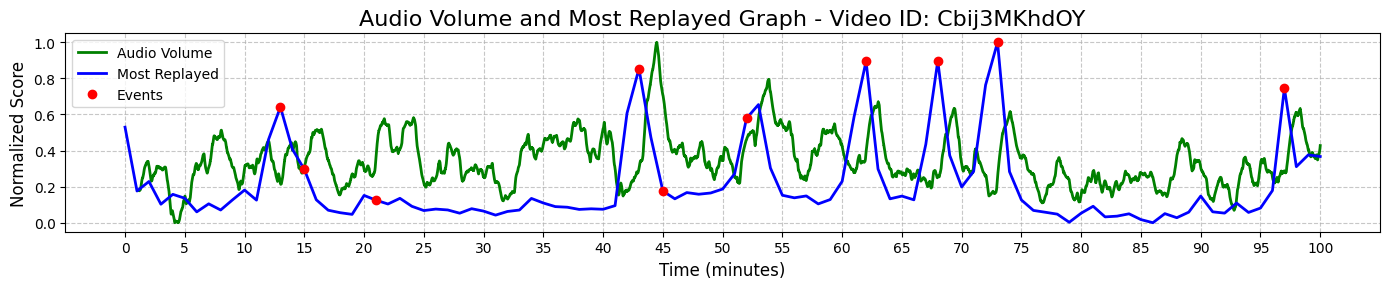

In [32]:
plt.figure(figsize=(14, 3))

# 오디오 볼륨 그래프
plt.plot(time_axis, moving_avg_normalize, color='green', linewidth=2, label='Audio Volume')

# Most Replayed 그래프
plt.plot(new_time / 60, normalized_scores, color='blue', linewidth=2, label='Most Replayed')

# 이벤트 포인트
plt.plot(np.array(event_lst), normalized_scores[event_lst], "o", color='red', label='Events')

plt.title(f'Audio Volume and Most Replayed Graph - Video ID: {video_id}', fontsize=16)
plt.xlabel('Time (minutes)', fontsize=12)
plt.ylabel('Normalized Score', fontsize=12)
plt.grid(True, linestyle='--', alpha=0.7)
plt.xticks(np.arange(0, total_duration_minutes + 1, 5))  # 5분 간격으로 x축 눈금 표시
plt.legend()
plt.tight_layout()
plt.show()

# Moving average

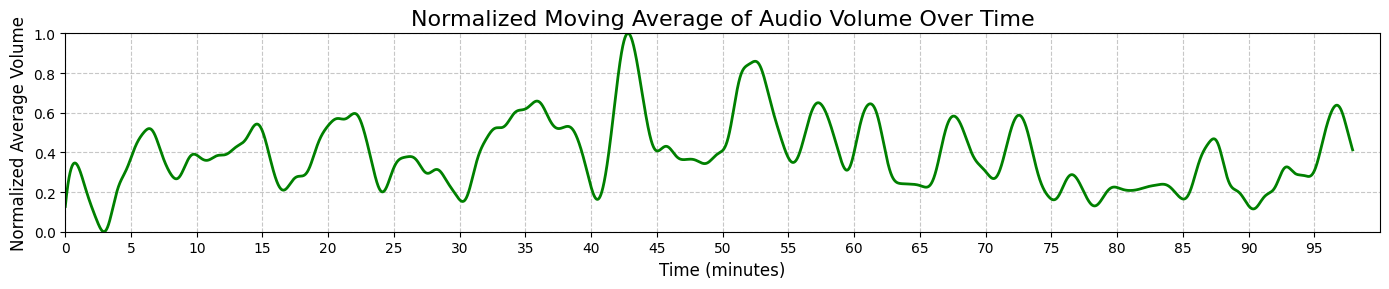

In [18]:
import numpy as np
import matplotlib.pyplot as plt

def moving_average(data, window_size):
    return np.convolve(data, np.ones(window_size), 'valid') / window_size

def normalize(data):
    return (data - np.min(data)) / (np.max(data) - np.min(data))

window_size = 5000  # 조절 가능
ma_rms = moving_average(rms_filtered, window_size)

# 0과 1 사이로 정규화
normalized_ma_rms = normalize(ma_rms)

# 결과를 완전히 왼쪽으로 이동
ma_times = times[:len(normalized_ma_rms)]

plt.figure(figsize=(14, 3))
plt.plot(ma_times, normalized_ma_rms, color='green', linewidth=2)
plt.title("Normalized Moving Average of Audio Volume Over Time", fontsize=16)
plt.xlabel("Time (minutes)", fontsize=12)
plt.ylabel("Normalized Average Volume", fontsize=12)
plt.grid(True, linestyle='--', alpha=0.7)
plt.xticks(np.arange(0, max_time + 5, 5))
plt.ylim(0, 1)  # y축 범위를 0에서 1로 설정
plt.xlim(0, max_time)  # x축 범위를 0부터 max_time까지로 설정
plt.tight_layout()
plt.show()

In [17]:
plt.figure(figsize=(14, 3))

# 오디오 볼륨 그래프
plt.plot(ma_times, normalized_ma_rms, color='green', linewidth=2, label='Audio Volume')

# Most Replayed 그래프
plt.plot(new_time / 60, normalized_scores, color='blue', linewidth=2, label='Most Replayed')

# 이벤트 포인트
plt.plot(np.array(event_lst), normalized_scores[event_lst], "o", color='red', label='Events')
# for group in grouped_points:
#     for i in range(len(group) -1 ):
#         plt.plot([group[i], group[i + 1]], [smoothed_intensity_scores[group[i]], smoothed_intensity_scores[group[i + 1]]], color='r', linewidth=2)

plt.title(f'Audio Volume and Most Replayed Graph - Video ID: {video_id}', fontsize=16)
plt.xlabel('Time (minutes)', fontsize=12)
plt.ylabel('Normalized Score', fontsize=12)
plt.grid(True, linestyle='--', alpha=0.7)
plt.xticks(np.arange(0, total_duration_minutes + 1, 5))  # 5분 간격으로 x축 눈금 표시
plt.legend()
plt.tight_layout()
plt.show()

NameError: name 'ma_times' is not defined

<Figure size 1400x300 with 0 Axes>

# 상관 관계

In [ ]:
len(smoothed_intensity_scores)

101

In [ ]:
target_scores = normalized_scores

In [ ]:
from scipy import interpolate
from scipy import stats


def find_optimal_window_size(window):
    ma_rms = moving_average(rms, window)
    normalized_ma_rms = normalize(ma_rms)
    ma_times = times[:len(normalized_ma_rms)]
    
    if len(normalized_ma_rms) > len(target_scores):
        long_data = normalized_ma_rms
        short_data = target_scores
        long_times = ma_times
        short_times = new_time / 60
    else:
        long_data = target_scores
        short_data = normalized_ma_rms
        long_times = new_time / 60
        short_times = ma_times
    
    f = interpolate.interp1d(short_times, short_data, kind='linear', fill_value='extrapolate')
    resampled_short_data = f(long_times)
    correlation, _ = stats.pearsonr(long_data, resampled_short_data)
    return correlation

In [ ]:
max_correlation = -1
optimal_window = 0

for window in range(100, 7000, 100):
    correlation = find_optimal_window_size(window)
    if correlation > max_correlation:
        max_correlation = correlation
        optimal_window = window
    print(f"Window: {window}, Correlation: {correlation}")

print(f"\nOptimal window size: {optimal_window}")
print(f"Maximum correlation: {max_correlation}")

Window: 100, Correlation: 0.04060027007585052
Window: 200, Correlation: 0.04737595385291381
Window: 300, Correlation: 0.05337337678016417
Window: 400, Correlation: 0.05915447102371909
Window: 500, Correlation: 0.06456178405925027
Window: 600, Correlation: 0.06973746195173698
Window: 700, Correlation: 0.07485986631087392
Window: 800, Correlation: 0.07997390252358492
Window: 900, Correlation: 0.08499038705345176
Window: 1000, Correlation: 0.08977115830632428
Window: 1100, Correlation: 0.09424021380237417
Window: 1200, Correlation: 0.09849775883032336
Window: 1300, Correlation: 0.10267963164895402
Window: 1400, Correlation: 0.10674522323880996
Window: 1500, Correlation: 0.11075036529450977
Window: 1600, Correlation: 0.11470001944674683
Window: 1700, Correlation: 0.11854757577324956
Window: 1800, Correlation: 0.12228456364095838
Window: 1900, Correlation: 0.12592139962827487
Window: 2000, Correlation: 0.12952302768641052
Window: 2100, Correlation: 0.13317889594705007
Window: 2200, Correlat